# NB3 — Teaching the Truncation Trick in MNIST GANs

**COMP3620 CW3 | Stage 3: Teach It | ~30 minutes**

**Research question:** *Does the truncation trick improve image quality at the cost of sample diversity in GANs?*

**Audience:** A student from another group who has only read the challenge statement.

> **Project status (important):** This is an executable teaching draft while NB1 and NB2 are unfinished. Sections labelled **TO INTEGRATE** must be updated with your group's real generator checkpoints, numeric results, and conclusions. Synthetic latent-space illustrations are **not** GAN experimental evidence. Never present them as NB2 outcomes.

**Suggested timings:** Introduction 3 min · Theory 6 min · Prediction 3 min · Sampling lab 6 min · Group experiment 5 min · Interpretation 4 min · Reflection 3 min.

### Learning objectives
After this notebook, you should be able to: (1) describe what a GAN generator does; (2) define latent truncation and distinguish it from clipping/scaling; (3) predict how truncated latent distributions differ; (4) interpret empirical evidence on digit clarity, within-class variation, and digit coverage; (5) recognize why a conclusion on MNIST may not generalize.

## 0. Setup and reproducibility

Run **Kernel → Restart & Run All**. `QUICK=True` avoids training and loads a cached TorchScript generator if one exists. If none exists, the notebook still runs a clearly labelled *latent-space teaching demo*, without pretending to show generated GAN digits. `QUICK=False` can train a small *illustrative* MNIST GAN and cache its generator; this teaching model is **not** a substitute for the controlled NB1/NB2 experiment.

The final group submission should use the exact same generator/truncation definition as NB1/NB2. The coursework asks for at least three seeds per experimental condition in the research notebooks.

In [14]:
%pip install torch torchvision

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 539.2/539.2 MB 27.4 MB/s  0:00:10m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 519.2/519.2 MB 27.0 MB/s  0:00:11m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.1/170.1 MB 51.2 MB/s  0:00:03m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.0/216.0 MB 55.7 MB/s  0:00:03m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.4/135.4 MB 46.2 MB/s  0:00:02m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.4/8.4 MB 52.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 404.9/404.9 MB 15.3 MB/s  0:00:17m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 60.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 MB 56.0 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 56.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 218.3/218.3 MB 66.2 MB/s  0:00:03m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB

In [15]:
%pip install numpy matplotlib


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [16]:
QUICK = True
SEED = 3620
LATENT_DIM = 100
TRUNCATION_LEVELS = [None, 2.0, 1.0, 0.5]  # None = no truncation
N_SAMPLES = 1024

from pathlib import Path
import csv
import math
import random
import numpy as np
import matplotlib.pyplot as plt

CACHE_DIR = Path("nb3_cache")
CACHE_DIR.mkdir(exist_ok=True)
GENERATOR_PATH = CACHE_DIR / "generator_scripted.pt"
GROUP_RESULTS_CSV = CACHE_DIR / "nb2_group_results.csv"
random.seed(SEED)
np.random.seed(SEED)
print("QUICK mode:", QUICK)
print("Generator checkpoint available:", GENERATOR_PATH.exists())
print("NB2 quantitative results available:", GROUP_RESULTS_CSV.exists())

QUICK mode: True
Generator checkpoint available: False
NB2 quantitative results available: False


## 1. GANs in one minute

A Generative Adversarial Network has two networks during training: a **generator** \(G(z)\) that maps noise \(z\) to an image, and a **discriminator** \(D(x)\) that tries to distinguish generated images from real MNIST examples. At inference time, the trained generator alone can produce new samples.

The **latent distribution** matters. Our teaching example uses independent standard-normal coordinates, \(z_j\sim\mathcal N(0,1)\). **The group's actual generator must be trained with the same type of latent input used at sampling time.**

A model trained using uniform noise should not silently be tested with standard-normal noise.

## 2. What exactly is the truncation trick?

For this notebook, truncation means **coordinate-wise rejection sampling** from a standard-normal prior: repeatedly draw \(z_j\sim\mathcal N(0,1)\) until \(|z_j|\leq t\). Thus, \(z_j\) follows the normal distribution **conditioned on** being in \([-t,t]\).

- `None`: original, untruncated \(\mathcal N(0,1)\).
- `t=2.0`: milder truncation.
- `t=0.5`: stronger truncation.

**Distinction:** clipping (`np.clip`) creates mass at the boundaries; scaling (`z*t`) shrinks all values; rejection sampling renormalizes the distribution within the accepted interval. These operations are not equivalent. The definition above is one particular choice and should be checked against NB2 before final submission.

**Theoretical expectation, not a guaranteed outcome:** stronger truncation may avoid unusual low-probability latent inputs and improve perceptual quality, but may reduce variety. This depends on the trained generator.

In [17]:
def sample_latent(n, dim, threshold=None, seed=0):
    """Independent coordinate-wise truncated N(0,1), via rejection sampling."""
    rng = np.random.default_rng(seed)
    if threshold is None:
        return rng.standard_normal((n, dim)).astype(np.float32)
    if threshold <= 0:
        raise ValueError("Truncation threshold must be > 0")
    out = rng.standard_normal((n, dim))
    mask = np.abs(out) > threshold
    while np.any(mask):
        out[mask] = rng.standard_normal(int(mask.sum()))
        mask = np.abs(out) > threshold
    return out.astype(np.float32)

# Built-in correctness checks
for t in [0.5, 1.0, 2.0]:
    z = sample_latent(128, 7, t, SEED)
    assert np.isfinite(z).all() and (np.abs(z) <= t).all()
print("Truncation sampler tests passed.")

Truncation sampler tests passed.


### Explore how truncation changes the latent distribution

This first experiment contains **no neural network**. It is an explanatory visualization of *inputs to* a generator, not evidence that digit images become clearer.

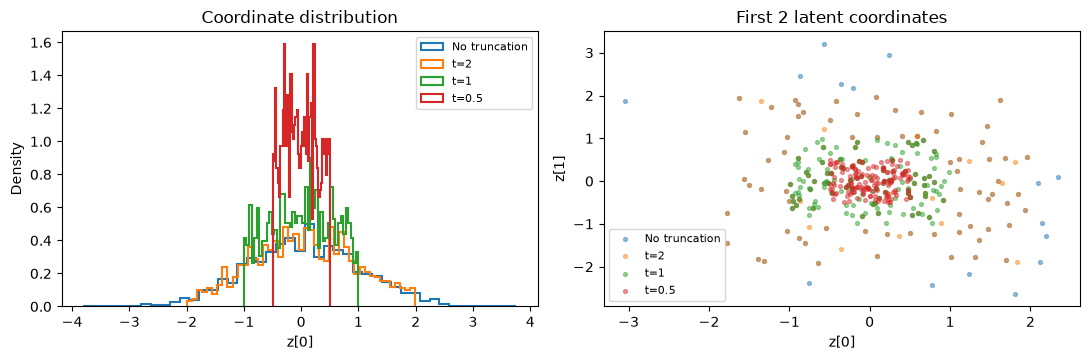

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
for t in TRUNCATION_LEVELS:
    z = sample_latent(N_SAMPLES, LATENT_DIM, t, seed=SEED)
    label = "No truncation" if t is None else f"t={t:g}"
    axes[0].hist(z[:, 0], bins=45, density=True, histtype="step", linewidth=1.5, label=label)
    axes[1].scatter(z[:150, 0], z[:150, 1], s=8, alpha=0.45, label=label)
axes[0].set(title="Coordinate distribution", xlabel="z[0]", ylabel="Density")
axes[1].set(title="First 2 latent coordinates", xlabel="z[0]", ylabel="z[1]")
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 3. Prediction exercise (3 minutes)

**Before running the next cell, write predictions in your own words.**

1. As threshold \(t\) decreases, should the variance of the latent coordinates increase or decrease?
2. Does that observation *prove* that MNIST handwriting variation will decrease? Why or why not?
3. Why could digit **coverage** (0–9) and **within-digit diversity** move differently?

**My predictions (fill in before seeing results):**

- P1: …
- P2: …
- P3: …

In [19]:
def mean_pairwise_l2(x, pairs=2000, seed=123):
    rng = np.random.default_rng(seed)
    a = rng.integers(len(x), size=pairs)
    b = rng.integers(len(x), size=pairs)
    return float(np.linalg.norm(x[a] - x[b], axis=1).mean())

print(f"{'Threshold':<18} {'Latent variance':>16} {'Mean pairwise L2':>20}")
for t in TRUNCATION_LEVELS:
    z = sample_latent(N_SAMPLES, LATENT_DIM, t, SEED)
    label = "None" if t is None else str(t)
    print(f"{label:<18} {float(z.var()):>16.3f} {mean_pairwise_l2(z):>20.3f}")

Threshold           Latent variance     Mean pairwise L2
None                          1.002               14.099
2.0                           0.774               12.395
1.0                           0.292                7.614
0.5                           0.080                4.006


**Discuss:** Smaller latent spread is an *input-space* property, not a measure of generated image quality. A nonlinear generator can react unpredictably, and different regions of latent space may represent different digits. Comparing real output samples is essential.

**Check on prediction 1:** Stronger truncation should reduce coordinate variance under this sampling definition. **Predictions 2–3:** Not necessarily; they require image-level evidence.

## 4. Real GAN image lab — connect the group's trained generator (TO INTEGRATE)

**Integration contract:** Export the group's generator as a TorchScript module at `nb3_cache/generator_scripted.pt`; it should accept a floating tensor of shape `[batch, LATENT_DIM]` and output MNIST images as `[batch,1,28,28]`, `[batch,28,28]`, or `[batch,784]`. Update `LATENT_DIM` and the output range if the group's architecture differs.

The TorchScript export must come from **your group's own trained model** (NB1/NB2). In `QUICK=True`, only inference is performed. There is intentionally **no fabricated image grid** if the checkpoint is absent.

For a matched comparison use a common random seed for every threshold; however, rejection sampling changes the draws, so it does not automatically create image-by-image pairings across thresholds.

In [20]:
def load_generator(path):
    import torch
    if not path.exists():
        return None
    model = torch.jit.load(str(path), map_location="cpu")
    model.eval()
    return model

def generate_images(generator, threshold, n=64, seed=SEED):
    import torch
    z = sample_latent(n, LATENT_DIM, threshold, seed)
    with torch.no_grad():
        result = generator(torch.from_numpy(z)).detach().cpu().numpy()
    result = result.reshape(n, 28, 28)
    # Expected output uses tanh: [-1,1]. Adapt to the real group model as needed.
    if result.min() < -0.05:
        result = (result + 1.0) / 2.0
    return np.clip(result, 0, 1)

def image_grid(images, ax, title, rows=4, cols=8):
    images = images[:rows * cols]
    canvas = np.zeros((rows*28, cols*28))
    for i, im in enumerate(images):
        r, c = divmod(i, cols)
        canvas[r*28:(r+1)*28, c*28:(c+1)*28] = im
    ax.imshow(canvas, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")

generator = load_generator(GENERATOR_PATH)
if generator is None:
    print("TO INTEGRATE: No group GAN checkpoint yet. The real-image comparison will appear after NB1/NB2 deliver it.")
else:
    fig, axes = plt.subplots(len(TRUNCATION_LEVELS), 1, figsize=(10, 12))
    for ax, t in zip(axes, TRUNCATION_LEVELS):
        images = generate_images(generator, t, n=32)
        image_grid(images, ax, "No truncation" if t is None else f"Threshold t={t}")
    plt.tight_layout()
    plt.show()

TO INTEGRATE: No group GAN checkpoint yet. The real-image comparison will appear after NB1/NB2 deliver it.


### Optional full-mode teaching GAN training (not the NB1/NB2 controlled result)

When `QUICK=False`, the cell below trains **one demonstration generator** from scratch on MNIST and exports it as TorchScript. This code is an illustrative teaching example and **must not be described as the group's multi-seed evidence**. It requires PyTorch and `torchvision`, plus access to MNIST (download or pre-cached). When the group provides its checkpoint, the final NB3 can remove this extra demonstration and use the team's actual reproducible training workflow.

`QUICK=True` never downloads data or trains in this section.

In [21]:
def train_demo_generator(epochs=2, batch_size=128, max_batches_per_epoch=120):
    import torch
    import torch.nn as nn
    from torch.utils.data import DataLoader
    from torchvision import datasets, transforms

    class DemoGenerator(nn.Module):
        def __init__(self):
            super().__init__()
            self.net = nn.Sequential(nn.Linear(LATENT_DIM, 128), nn.LeakyReLU(0.2),
                                     nn.Linear(128, 256), nn.LeakyReLU(0.2),
                                     nn.Linear(256, 784), nn.Tanh())
        def forward(self, z):
            return self.net(z).reshape(-1, 1, 28, 28)

    class DemoDiscriminator(nn.Module):
        def __init__(self):
            super().__init__()
            self.net = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.LeakyReLU(0.2),
                                     nn.Linear(256, 128), nn.LeakyReLU(0.2), nn.Linear(128, 1))
        def forward(self, x):
            return self.net(x)

    torch.manual_seed(SEED)
    G = DemoGenerator()
    D = DemoDiscriminator()
    opt_g = torch.optim.Adam(G.parameters(), lr=0.0002, betas=(0.5, 0.999))
    opt_d = torch.optim.Adam(D.parameters(), lr=0.0002, betas=(0.5, 0.999))
    bce = nn.BCEWithLogitsLoss()
    data = datasets.MNIST(root=str(CACHE_DIR / "data"), train=True, download=True,
                          transform=transforms.Compose([transforms.ToTensor(),
                                                       transforms.Normalize((0.5,), (0.5,))]))
    loader = DataLoader(data, batch_size=batch_size, shuffle=True, num_workers=0)
    for epoch in range(epochs):
        for j, (real, _) in enumerate(loader):
            if j >= max_batches_per_epoch:
                break
            bs = real.shape[0]
            z = torch.randn(bs, LATENT_DIM)
            fake = G(z)
            opt_d.zero_grad()
            loss_d = bce(D(real), torch.ones(bs, 1)) + bce(D(fake.detach()), torch.zeros(bs, 1))
            loss_d.backward(); opt_d.step()
            opt_g.zero_grad()
            loss_g = bce(D(G(torch.randn(bs, LATENT_DIM))), torch.ones(bs, 1))
            loss_g.backward(); opt_g.step()
        print(f"Demonstration epoch {epoch+1}: D loss={loss_d.item():.3f}, G loss={loss_g.item():.3f}")
    G.eval()
    traced = torch.jit.trace(G, torch.randn(2, LATENT_DIM))
    traced.save(str(GENERATOR_PATH))
    return G

if not QUICK:
    print("Full teaching demo: training an illustrative GAN. Do not use as NB1/NB2 evidence.")
    train_demo_generator()
else:
    print("QUICK=True: skipped GAN training and network access.")

QUICK=True: skipped GAN training and network access.


## 5. Measure quality and diversity — results from NB2 (TO INTEGRATE)

The main research question needs **separate operational definitions**:

- **Digit clarity (proxy):** accuracy/confidence of an **independent** MNIST classifier on generated images. Classifier confidence is *not* a ground-truth quality score; a classifier can be confidently wrong.
- **Handwriting variation:** within-predicted-digit diversity (e.g. feature-space dispersion within each class). Pixel distances are susceptible to position/brightness changes and need cautious interpretation.
- **Digit coverage:** how many classes (0–9) appear and how evenly they are represented. A nonzero predicted count is not the same as high-quality coverage.

Use the same generator checkpoint and image count across truncation thresholds; vary *only* the sampling truncation. Analyse results for at least three random generator-training seeds from NB1/NB2 and report dispersion. If using a classifier, validate its performance on held-out MNIST before using its labels for generated images.

**Data contract:** Once teammates finish, create `nb3_cache/nb2_group_results.csv` with headers `seed,threshold,clarity,variation,coverage`. Store untruncated results under threshold `none`; numerical truncation thresholds as `2.0`, `1.0`, etc. Values must come from your real NB2 analysis and be accompanied by metric definitions and units.

In [22]:
if not GROUP_RESULTS_CSV.exists():
    print("TO INTEGRATE: nb2_group_results.csv is not yet available; no real quantitative findings are shown.")
else:
    with GROUP_RESULTS_CSV.open(newline="") as f:
        rows = list(csv.DictReader(f))
    expected = {"seed", "threshold", "clarity", "variation", "coverage"}
    assert rows and expected.issubset(rows[0]), f"Missing expected CSV columns: {expected}"
    thresholds = list(dict.fromkeys(r["threshold"] for r in rows))
    metrics = ["clarity", "variation", "coverage"]
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.7))
    for ax, metric in zip(axes, metrics):
        means, deviations = [], []
        for t in thresholds:
            vals = np.array([float(r[metric]) for r in rows if r["threshold"] == t])
            if len(vals) < 3:
                print(f"WARNING: {metric}, t={t} contains fewer than 3 seeds")
            means.append(vals.mean())
            deviations.append(vals.std(ddof=1) if len(vals) > 1 else 0)
        ax.errorbar(range(len(thresholds)), means, yerr=deviations, marker="o", capsize=4)
        ax.set_xticks(range(len(thresholds)), thresholds)
        ax.set(xlabel="Truncation threshold", ylabel=metric, title=f"NB2: {metric} (mean ± SD)")
    plt.tight_layout(); plt.show()
    print("Loaded empirical NB2 rows:", len(rows))

TO INTEGRATE: nb2_group_results.csv is not yet available; no real quantitative findings are shown.


## 6. Interpretation — distinguish evidence from explanation (TO INTEGRATE)

When NB2 data are available, replace the prompts below with the actual conclusions, complete with figures/tables and seed-to-seed variability.

1. **What we observed:** State actual trends in clarity, handwriting variation, and digit coverage (or say there was no clear trend).
2. **What theory predicts:** Chapter 15.3 motivates a possible quality/diversity trade-off from sampling concentrated latent regions.
3. **Alternative explanations:** A poorly trained GAN may have mode collapse *before* truncation; classifier-based scores may reward easy-to-classify but repetitive images; coordinate-wise truncation may change latent norms in a high-dimensional way; smaller latent spread need not imply monotonic variation in image space.
4. **Sensitivity:** Does the finding persist with a different truncation threshold set, sample size, or model-training seed? Use the actual NB2 check.
5. **Scope:** Conclusions apply to the particular MNIST GAN, truncation method, trained seeds, and metrics tested. Do not generalize to medical images, StyleGAN, or other datasets without additional evidence.

**No experiment results are asserted in this draft.**

## 7. Reflection exercise (3 minutes)

Imagine a developer wants to generate many *distinct* handwritten digit styles, but another developer mainly wants a small collection of highly legible digit illustrations.

**Exercise:** Based on the plots and final NB2 metrics, recommend a truncation threshold (including `None`) to each developer. Cite **one numerical result and one limitation** for each choice.

**Your answer:**

- Developer A (diverse handwriting): …
- Developer B (legible illustrations): …
- Trade-off or uncertainty: …

**Self-check / instructor guidance:** A persuasive answer references measured quality and diversity rather than a preconceived rule that stronger truncation is always better. If the confidence intervals or seed spreads overlap substantially, say the evidence is inconclusive.

## 8. Takeaways and references

- GANs map latent samples into synthetic images.
- Truncation changes the **sampling distribution**, not the generator weights, in this experiment.
- Quality, within-class diversity, and digit coverage are distinct outcomes; one metric cannot stand in for all three.
- The direction and size of the trade-off must be established from the **actual** group data.

**Project reference:** Simon J. D. Prince, *Understanding Deep Learning*, Chapter 15, Section 15.3 (Truncation).  
**Implementation references (for learning, not a claim of direct reuse):** [Zackory/Keras-MNIST-GAN](https://github.com/Zackory/Keras-MNIST-GAN), [Garima13a/MNIST_GAN](https://github.com/Garima13a/MNIST_GAN).

### Integration checklist before submission

- [ ] Align sampler, prior, and `LATENT_DIM` with NB1/NB2.
- [ ] Insert the real, trained group generator exported in a loadable format.
- [ ] Insert real NB2 results from ≥3 seeds, plus metric definitions and uncertainty.
- [ ] Replace placeholders in interpretation with evidence-based conclusions.
- [ ] Ensure the full experiment/training code required by the group is present and accurately reflected in caches.
- [ ] Run on school `condaenv/dl2026`: clean kernel `QUICK=True` under 5 minutes; verify `QUICK=False` separately.
- [ ] Include notebook, checkpoint(s) and results in submission budget (100 MB total Gradescope limit).